In [16]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

# New simplified imports
from movebench.study import Study
from movebench.ssf import grouped_nll

In [18]:
# Load a study - all the CSV parsing, timestamp handling, etc. is automatic
study = Study.load('5a280544-06db-4c85-9713-842547972edd')
print(study)

Study('5a280544-06db-4c85-9713-842547972edd')


In [20]:
# First call computes per-layer stats if missing, subsequent calls use cache
train_ds = study.chip_dataset(split='train', 
                            #   force_normalize=True
                              )
print(f"Train dataset: {len(train_ds)} samples")

# Load one sample
x, mask, transform, crs = train_ds[0]
print(f"Sample shape: {x.shape}")

Train dataset: 1521 samples
Sample shape: torch.Size([72, 79, 77])


In [21]:
len(x[mask]) / len(x.flatten())

0.8349270279650026

(array([5.40000e+01, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        6.00000e+00, 8.00000e+00, 3.10000e+01, 5.96000e+02, 7.38400e+03,
        1.27970e+04, 2.71960e+04, 9.18880e+04, 1.65042e+05, 3.77710e+04,
        1.06000e+04, 1.11470e+04, 6.76000e+02, 3.59000e+02, 7.20000e+01,
        3.00000e+00, 2.00000e+00, 2.00000e+00, 7.00000e+00, 1.10000e+01,
        1.10000e+01, 6.00000e+00, 3.00000e+00, 0.00000e+00, 6.00000e+00]),
 array([-23.29460526, -22.59523964, -21.89587593, -21.19651031,
        -20.49714661, -19.79778099, -19.09841537, -18.39905167,
        -17.69968796, -17.00032234, -16.30095673, -15.60159302,
        -14.9022274 , -14.20286274, -13.50349808, -12.80413342,
        -12.

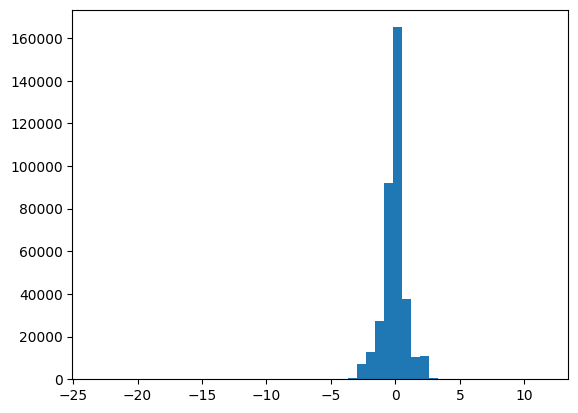

In [22]:
import matplotlib.pyplot as plt

plt.hist(x[mask], bins=50)

In [23]:
# Inspect the per-layer normalization stats (auto-generated by chip_dataset)
import json

stats_file = study._study_dir / "normalization" / "stats.json"
with open(stats_file) as f:
    stats = json.load(f)

print(f"Normalization stats stored in: {stats_file}")
print(f"Layers with stats: {list(stats.keys())}")
print(f"\nExample - era5_land bands:")
for band, vals in list(stats.get('era5_land', {}).get('bands', {}).items())[:3]:
    print(f"  {band}: mean={vals['mean']:.4f}, std={vals['std']:.4f}")

Normalization stats stored in: /data/vision/beery/scratch/justin/movebench/studies/5a280544-06db-4c85-9713-842547972edd/normalization/stats.json
Layers with stats: ['modis_lst', 'modis_vi', 'modis_ndsi', 'modis_bai', 'era5_land', 'era5', 'dem', 'modis_cvf_tree', 'modis_cvf_nontree', 'modis_cvf_nonveg', 'hii', 'bioclim', 'dynamic_world']

Example - era5_land bands:
  temperature_2m: mean=272.9991, std=5.4522
  dewpoint_temperature_2m: mean=269.1833, std=5.0397
  total_precipitation: mean=0.0004, std=0.0011


In [24]:
# Create SSF dataset - one line!
ssf_ds = study.ssf_dataset(split='train')
print(f"SSF dataset: {len(ssf_ds)} samples")

# Load one sample: (C, num_candidates+1) where C=72 channels, 100 pseudo + 1 true endpoint
step_pixels, valid_pixels, chip_transform, chip_crs = ssf_ds[0]
print(f"Step pixels shape: {step_pixels.shape}")

<string>:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


SSF dataset: 1513 samples
Step pixels shape: torch.Size([72, 101])


In [25]:
# Inspect features for the first candidate
print("Features for first candidate point:")
print(step_pixels[:, 0])
print("\nValid mask:")
print(valid_pixels[:, 0])

Features for first candidate point:
tensor([-1.3237, -2.6514, -0.8301, -0.8839,  0.5082, -0.2653,    -inf,    -inf,
           -inf,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf,
           -inf,    -inf, -0.8636, -0.1286,  2.0378, -0.8081,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
        -0.2878,  0.9446, -1.1383,  0.1828, -0.8558, -0.0267,  0.8839, -1.1190,
        -1.1759,  0.2440, -1.1725, -1.3182,  0.0651, -1.1380,  0.4596,  0.2667,
         0.7569, -0.2579, -0.1119,  0.1889, -0.0563,  0.2733,  0.7885, -0.1622,
        -0.3713, -0.3859, -0.3909, -0.3180, -0.5438, -0.1813,  0.2464,  0.5612])

Valid mask:
tensor([ True,  True,  True,  True,  True,  True, False, False, False, False,
        False, False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  Tr

---
## Train SSF Model

Train a conditional logistic regression model directly using the SSFDataset.

In [26]:
# Extract features from SSFDataset
# This iterates through the dataset once to build feature matrices

def extract_ssf_features(dataset, num_workers=8):
    """Extract all features from an SSFDataset into tensors."""
    loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=num_workers)
    
    all_xs = []
    all_masks = []
    
    for step_pixels, valid_pixels, _, _ in tqdm(loader, desc="Extracting features"):
        all_xs.append(step_pixels)
        all_masks.append(valid_pixels)
    
    # Stack: (N, C, num_candidates+1)
    X = torch.cat(all_xs, dim=0)
    masks = torch.cat(all_masks, dim=0)
    
    # Reshape to (N * (num_candidates+1), C) for regression
    N, C, K = X.shape
    X = X.permute(0, 2, 1).reshape(-1, C)
    masks = masks.permute(0, 2, 1).reshape(-1, C)
    
    # Labels: last candidate (index K-1) is the true endpoint
    y = torch.zeros(N * K, dtype=torch.long)
    y[K-1::K] = 1  # Every K-th element starting from K-1
    
    # Group indices for conditional logistic regression
    starts = torch.arange(0, N * K, K)
    ends = torch.arange(K, N * K + 1, K)
    
    return X, masks, y, starts, ends

# Extract train and test features
train_ssf = study.ssf_dataset(split='train')
test_ssf = study.ssf_dataset(split='test')

X_tr, masks_tr, y_tr, starts_tr, ends_tr = extract_ssf_features(train_ssf)
X_te, masks_te, y_te, starts_te, ends_te = extract_ssf_features(test_ssf)

print(f"Train: {X_tr.shape}, Test: {X_te.shape}")

<string>:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
Extracting features:  21%|██        | 457/2155 [08:08<30:16,  1.07s/it]


KeyboardInterrupt: 

In [27]:
# Clean features: fill invalid values with 0 (approx mean after normalization)
def clean_features(X, masks):
    X_clean = torch.where(masks, X, torch.tensor(0.0))
    X_clean = torch.nan_to_num(X_clean, nan=0.0, posinf=0.0, neginf=0.0)
    return X_clean

X_tr_clean = clean_features(X_tr, masks_tr)
# X_te_clean = clean_features(X_te, masks_te)

print(f"Features per sample: {X_tr_clean.shape[1]}")
# print(f"Train groups: {len(starts_tr)}, Test groups: {len(starts_te)}")

Features per sample: 72


In [ ]:
# Train conditional logistic regression
num_features = X_tr_clean.shape[1]
beta = torch.zeros(num_features, dtype=torch.float32, requires_grad=True)
opt = torch.optim.Adam([beta], lr=1e-2, weight_decay=1e-3)

for step in range(1000):
    opt.zero_grad()
    loss = grouped_nll(beta, X_tr_clean, y_tr, starts_tr, ends_tr)
    loss.backward()
    opt.step()
    
    if step % 100 == 0:
        with torch.no_grad():
            nll_tr = grouped_nll(beta, X_tr_clean, y_tr, starts_tr, ends_tr).item()
            # nll_te = grouped_nll(beta, X_te_clean, y_te, starts_te, ends_te).item()
            print(f"Step {step:4d} | Train NLL: {nll_tr:.4f}") # | Test NLL: {nll_te:.4f}")

In [ ]:
# Inspect learned coefficients
from movebench.config import get_channel_indices, LAYERS

print("Top 10 coefficients by magnitude:\n")

# Build channel names from layer config
indices = get_channel_indices()
channel_names = []
for name, (start, end) in indices.items():
    layer = LAYERS[name]
    if layer.categorical:
        for i in range(layer.num_classes):
            channel_names.append(f"{name}_class{i}")
    else:
        for band in layer.bands:
            channel_names.append(f"{name}_{band}")

beta_np = beta.detach().numpy()
sorted_idx = abs(beta_np).argsort()[::-1]

for i in sorted_idx[:10]:
    print(f"{channel_names[i]:40s} {beta_np[i]:+.4f}")